# WP12 — İki gerçek v2 hata kaydı
Yalnız kayıt okuma ve offline teşhis. Model/API/yeniden deneme yok. Genel FAILED_OR_TIMED_OUT etiketi gerçek exception yerine yorumlanmaz.

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();Q=ROOT/'reports/qa/WP12/gemma1b_v2_failure_review'
rows=json.loads((Q/'run_diagnoses.json').read_text(encoding='utf-8'));df=pd.DataFrame(rows)
display(df[['run_id','confirmed_failure','failure_stage','server_version','metadata_HTTP_exact_status','inference_attempts','server_model_residency']].T)
for r in rows:print(r['run_id'],r['exception'])

20261108_042856_aa8562b748f84e2e997f898e2001b6e7 System.Management.Automation.RuntimeException: MODEL_DIGEST_MISMATCH: do not silently switch model
20261108_042906_1ffecdc7c9e64cc1bee7dee3c5263a30 System.Management.Automation.RuntimeException: MODEL_DIGEST_MISMATCH: do not silently switch model


,0,1
run_id,20261108_042856_aa8562b748f84e2e997f898e2001b6e7,20261108_042906_1ffecdc7c9e64cc1bee7dee3c5263a30
confirmed_failure,MODEL_DIGEST_MISMATCH,MODEL_DIGEST_MISMATCH
failure_stage,DIGEST_GUARD_BEFORE_API_PS_BEFORE_MEMORY_GATE_...,DIGEST_GUARD_BEFORE_API_PS_BEFORE_MEMORY_GATE_...
server_version,0.40.6,0.40.6
metadata_HTTP_exact_status,UNKNOWN_NOT_LOGGED,UNKNOWN_NOT_LOGGED
inference_attempts,0,0
server_model_residency,UNKNOWN_NO_API_PS_RESPONSE_OR_SERVER_LOAD_LOG,UNKNOWN_NO_API_PS_RESPONSE_OR_SERVER_LOAD_LOG


**Yorum:**Her iki kayıt aynı digest guard hatasında durdu. API version/tags erişimi var; tam HTTP status kaydedilmemiş. Chat isteği gönderilmedi. Önceden yüklü model durumunu api/ps cevabı olmadan UNKNOWN tutuyoruz.

,run_id,RAM_available_GiB,RAM_deficit_MiB,GPU_free_MiB,commit_available_GiB,memory_gate_executed,initial_combined_gate_recomputed_pass
0,20261108_042856_aa8562b748f84e2e997f898e2001b6e7,2.404907,97.375,3935,13.749985,False,False
1,20261108_042906_1ffecdc7c9e64cc1bee7dee3c5263a30,2.395996,106.500,3935,13.753437,False,False


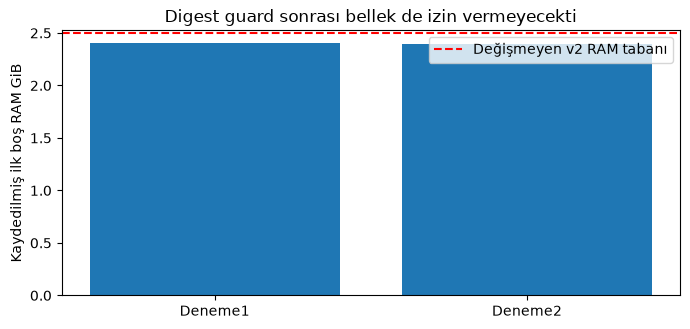

In [2]:
display(df[['run_id','RAM_available_GiB','RAM_deficit_MiB','GPU_free_MiB','commit_available_GiB','memory_gate_executed','initial_combined_gate_recomputed_pass']])
fig,ax=plt.subplots(figsize=(7,3.4));ax.bar(['Deneme1','Deneme2'],df['RAM_available_GiB']);ax.axhline(2.5,color='red',ls='--',label='Değişmeyen v2 RAM tabanı');ax.set_ylabel('Kaydedilmiş ilk boş RAM GiB');ax.set_title('Digest guard sonrası bellek de izin vermeyecekti');ax.legend();fig.tight_layout();F=ROOT/'reports/figures/WP12/gemma1b_v2_failure_review';F.mkdir(parents=True,exist_ok=True);fig.savefig(F/'recorded_memory_gates.png',dpi=150);plt.show()

**Yorum:**Betiğin bellek kapısına ulaşılmadı; tablo kayıtlı ilk ölçümü bağımsız yeniden hesaplıyor. RAM her iki durumda2,5GiB altında. Eşik veya timeout değişmiyor. Bu grafik modelin bellek tüketimi değildir.

In [3]:
display(pd.DataFrame([json.loads((Q/'digest_semantics_evidence.json').read_text(encoding='utf-8'))]).T)
display(pd.DataFrame([json.loads((Q/'minimal_correction_PROPOSED_ONLY.json').read_text(encoding='utf-8'))]).T)
print((Q/'diagnosis_tests.txt').read_text(encoding='utf-8'))

test_different_exception_not_inferred (test_wp12_gemma_failure_diagnosis.DiagnosisTests.test_different_exception_not_inferred) ... ok
test_different_script_requires_manual_review (test_wp12_gemma_failure_diagnosis.DiagnosisTests.test_different_script_requires_manual_review) ... ok
test_exact_HTTP_status_not_fabricated (test_wp12_gemma_failure_diagnosis.DiagnosisTests.test_exact_HTTP_status_not_fabricated) ... ok
test_exact_failure_not_timeout (test_wp12_gemma_failure_diagnosis.DiagnosisTests.test_exact_failure_not_timeout) ... ok
test_memory_recomputed_not_executed (test_wp12_gemma_failure_diagnosis.DiagnosisTests.test_memory_recomputed_not_executed) ... ok
test_no_inference_or_load_claim (test_wp12_gemma_failure_diagnosis.DiagnosisTests.test_no_inference_or_load_claim) ... ok
test_proposed_source_binding_offline_only (test_wp12_gemma_failure_diagnosis.DiagnosisTests.test_proposed_source_binding_offline_only) ... ok
test_two_original_manifests (test_wp12_gemma_failure_diagnosis.Diagnos

,0
local_wrapper_manifest_file_sha256,sha256:313f48e331f7326ce703657512ab64022d8813b...
API_model_digest_in_both_records,sha256:97558784bdc9175075a72655bf360b15da17df6...
source_manifest_content_sha256,sha256:97558784bdc9175075a72655bf360b15da17df6...
config_identical,True
weight_template_license_params_layers_identical,True
weight_content_rehashed_this_review,False
metadata_only_read,True


,0
status,REPORT_ONLY_NOT_APPLIED
scope,identity binding correction only; no new memor...
local_wrapper_manifest_file_sha256,sha256:313f48e331f7326ce703657512ab64022d8813b...
expected_API_model_digest,sha256:97558784bdc9175075a72655bf360b15da17df6...
required_validation,explicit local-wrapper -> source-manifest -> s...
required_consistency_updates_if_implemented,"[future runner expected API digest, future con..."
guard_not_removed,True
no_arbitrary_digest_acceptance,True
memory_thresholds_unchanged,"{'RAM_bytes': 2684354560, 'GPU_MiB': 2048, 'co..."
HTTP_timeout_seconds_unchanged,60


**Yorum:**Yerel sarmalayıcı313f… ile API/kaynak manifest9755… farklı kimlik nesneleridir. Küçük metadata zinciri aynı config/layer içeriğini doğruluyor. Öneri yalnız kimlik alanlarını ayırmak; uygulanmadı.8 test gerçek kayıt teşhisini sınadı, inference başarısını değil. WP13 ve19×3 başlamadan burada durulur.